# Mobile Games A/B Testing: Evaluating the Impact of Progression Design on Player Retention
This notebook analyzes an A/B test from the Cookie Cats mobile game to evaluate whether moving the first progression gate from level 30 to level 40 improves player retention.

The goal is not only to compare control and treatment groups statistically, but also to interpret the results in a product decision-making context.

## Business Context
This analysis evaluates whether moving the first gate in Cookie Cats from level 30 to level 40 improves player retention.

The product decision is meaningful because progression barriers can influence both early frustration and long-term engagement. A gate that appears less restrictive may improve short-term experience, but it may also reduce challenge and affect retention negatively.

## Experiment Setup
- **Control group:** gate at level 30 (`gate_30`)
- **Treatment group:** gate at level 40 (`gate_40`)
- **Primary metrics:** `retention_1`, `retention_7`
- **Behavioral metric:** `sum_gamerounds`

The goal is to understand whether the treatment leads to better player retention and more favorable behavioral outcomes.

This dataset includes A/B test results of Cookie Cats to examine what happens when the first gate in the game was moved from level 30 to level 40. When a player installed the game, he or she was randomly assigned to either gate_30 or gate_40.

The variables are:

userid: A unique number that identifies each player.

version: Whether the player was put in the control group (gate_30 - a gate at level 30) or the group with the moved gate (gate_40 - a gate at level 40).

sum_gamerounds: the number of game rounds played by the player during the first 14 days after install.

retention_1: Did the player come back and play 1 day after installing?

retention_7: Did the player come back and play 7 days after installing?

 Specifically, the project seeks to determine whether moving the gate (a progression barrier) from level 30 to level 40 improves player retention rates.
 Objectives

Assess Player Retention:

Measure and compare the retention rates for players subjected to different gate levels (level 30 and level 40) at both day 1 and day 7 intervals.

Evaluate the Impact of Game Design Changes:

Understand how altering the game's progression by moving the gate affects player behavior and engagement.

Provide Data-Driven Insights:

Use statistical analysis to provide insights into player retention, helping game designers make informed decisions.



Here are the steps to download the Cookie Cats dataset and perform A/B testing:

## Data Review

Before comparing groups, I first check the dataset structure, summary statistics, missing values, and group balance. This helps confirm that the experiment data is usable and that the two versions can be compared reliably.

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/kaggle/input/datasets/esraugurca/cookie-cats1-csv/cookie_cats 3.csv')

# Preview the dataset
print(df.head())

# Summary statistics
print(df.describe())

# Check for missing values
print(df.isnull().sum())

# Duplicated
print("Duplicate user IDs:", df['userid'].duplicated().sum())
print("Duplicate rows:", df.duplicated().sum())


df.nlargest(
    10, 'sum_gamerounds'
)[['userid', 'version', 'sum_gamerounds']]

   userid  version  sum_gamerounds  retention_1  retention_7
0     116  gate_30               3        False        False
1     337  gate_30              38         True        False
2     377  gate_40             165         True        False
3     483  gate_40               1        False        False
4     488  gate_40             179         True         True
             userid  sum_gamerounds
count  9.018900e+04    90189.000000
mean   4.998412e+06       51.872457
std    2.883286e+06      195.050858
min    1.160000e+02        0.000000
25%    2.512230e+06        5.000000
50%    4.995815e+06       16.000000
75%    7.496452e+06       51.000000
max    9.999861e+06    49854.000000
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64
Duplicate user IDs: 0
Duplicate rows: 0


,userid,version,sum_gamerounds
57702,6390605,gate_30,49854
7912,871500,gate_30,2961
29417,3271615,gate_40,2640
43671,4832608,gate_30,2438
48188,5346171,gate_40,2294
46344,5133952,gate_30,2251
87007,9640085,gate_30,2156
36933,4090246,gate_40,2124
88328,9791599,gate_40,2063
6536,725080,gate_40,2015


In [2]:
# Compare player activity with and without the extreme outlier

print("Original group statistics:")
print(
    df.groupby('version')['sum_gamerounds']
    .agg(['count', 'mean', 'median', 'max'])
)

# Exclude only the single largest observation
df_without_outlier = df.drop(
    df['sum_gamerounds'].idxmax()
)

print("\nWithout the largest observation:")
print(
    df_without_outlier.groupby('version')['sum_gamerounds']
    .agg(['count', 'mean', 'median', 'max'])
)

Original group statistics:
         count       mean  median    max
version                                 
gate_30  44700  52.456264    17.0  49854
gate_40  45489  51.298776    16.0   2640

Without the largest observation:
         count       mean  median   max
version                                
gate_30  44699  51.342111    17.0  2961
gate_40  45489  51.298776    16.0  2640


## Group Balance

A/B tests require reasonably balanced groups. I check the number of unique users in each version to confirm that the control and treatment groups are comparable in size.

In [3]:
df.groupby("version")[["userid"]].nunique()

,userid
version,
gate_30,44700
gate_40,45489


In [4]:
# Check the unique values in the 'version' column
print(df['version'].unique())

# Convert 'version' to categorical type for analysis
df['version'] = df['version'].astype('category')

# Create separate dataframes for each group
gate_30 = df[df['version'] == 'gate_30']
gate_40 = df[df['version'] == 'gate_40']

['gate_30' 'gate_40']


In [5]:
# Compare mean retention rate for day 1 and day 7
print("gate 30: ", gate_30[['retention_1', 'retention_7']].mean())
print("gate 40: ", gate_40[['retention_1', 'retention_7']].mean())

gate 30:  retention_1    0.448188
retention_7    0.190201
dtype: float64
gate 40:  retention_1    0.442283
retention_7    0.182000
dtype: float64


## Retention Comparison

I first compare the average day-1 and day-7 retention rates across the two groups. This provides an initial view of whether the treatment appears to improve player return behavior.

/opt/conda/lib/python3.10/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)
/opt/conda/lib/python3.10/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


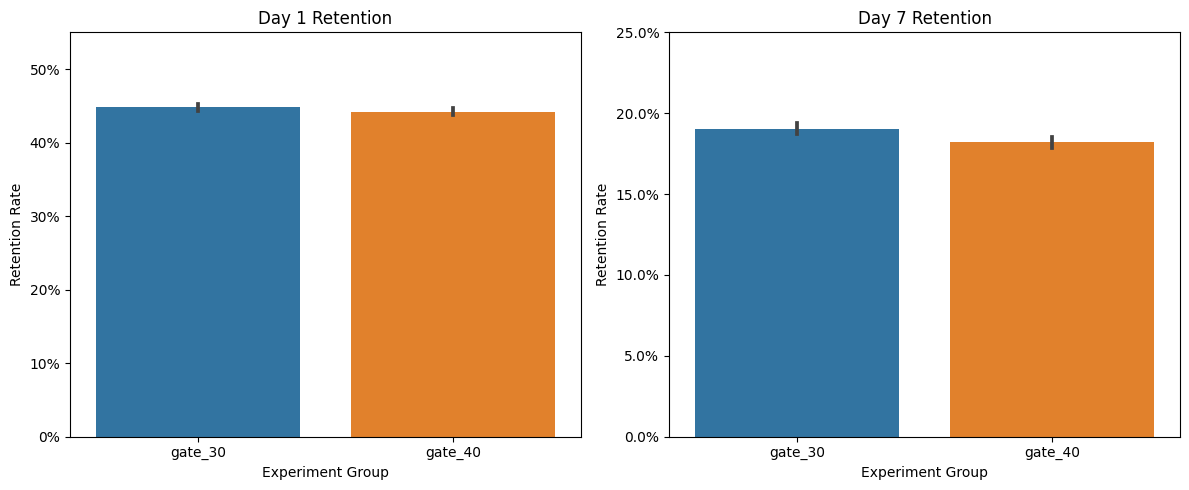

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metric, title in zip(
    axes,
    ['retention_1', 'retention_7'],
    ['Day 1 Retention', 'Day 7 Retention']
):
    sns.barplot(
        data=df,
        x='version',
        y=metric,
        errorbar=('ci', 95),
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Experiment Group')
    ax.set_ylabel('Retention Rate')
    ax.yaxis.set_major_formatter(
        PercentFormatter(1)
    )
    ax.set_ylim(0, 0.55 if metric == 'retention_1' else 0.25)

plt.tight_layout()
plt.show()

Initial results suggest that `gate_30` performs slightly better than `gate_40` on both day-1 and day-7 retention. The difference appears larger for day-7 retention, which may indicate that moving the gate to level 40 weakens medium-term engagement rather than improving it.

## Hypothesis

For each retention metric, I test the following:

- **Null hypothesis (H0):** Retention is the same in the `gate_30` and `gate_40` groups.
- **Alternative hypothesis (H1):** Retention differs between the two groups.

I focus especially on `retention_7`, since medium-term retention is usually more relevant for product decisions than very short-term return behavior.

In [7]:
import numpy as np
from statsmodels.stats.proportion import proportions_ztest

# Day 1 retention
success_day1 = np.array([
    gate_30["retention_1"].sum(),
    gate_40["retention_1"].sum()
])

nobs_day1 = np.array([
    gate_30["retention_1"].count(),
    gate_40["retention_1"].count()
])

z_stat_day1, p_val_day1 = proportions_ztest(success_day1, nobs_day1)

print("Day 1 retention")
print("z-statistic:", z_stat_day1)
print("p-value:", p_val_day1)

Day 1 retention
z-statistic: 1.7840862247974725
p-value: 0.07440965529691913


In [8]:
# Day 7 retention
success_day7 = np.array([
    gate_30["retention_7"].sum(),
    gate_40["retention_7"].sum()
])

nobs_day7 = np.array([
    gate_30["retention_7"].count(),
    gate_40["retention_7"].count()
])

z_stat_day7, p_val_day7 = proportions_ztest(success_day7, nobs_day7)

print("\nDay 7 retention")
print("z-statistic:", z_stat_day7)
print("p-value:", p_val_day7)


Day 7 retention
z-statistic: 3.164358912748191
p-value: 0.001554249975614329


In [9]:
import numpy as np

for metric in ['retention_1', 'retention_7']:
    a = df.loc[df['version'] == 'gate_30', metric].dropna()
    b = df.loc[df['version'] == 'gate_40', metric].dropna()

    p_a, p_b = a.mean(), b.mean()
    difference = p_a - p_b

    se = np.sqrt(
        p_a * (1 - p_a) / len(a)
        + p_b * (1 - p_b) / len(b)
    )

    lower = difference - 1.96 * se
    upper = difference + 1.96 * se

    print(f"\n{metric}")
    print(f"Difference: {difference:.2%}")
    print(f"95% CI: [{lower:.2%}, {upper:.2%}]")


retention_1
Difference: 0.59%
95% CI: [-0.06%, 1.24%]

retention_7
Difference: 0.82%
95% CI: [0.31%, 1.33%]


## Interpretation of Results

The difference in day-1 retention between the control and treatment groups is **not statistically significant** at the 5% level (**z = 1.784, p = 0.074**). This means there is not enough evidence to conclude that moving the gate from level 30 to level 40 changed short-term retention in a meaningful way.

Moving the gate from level 30 to level 40 does not produce a statistically significant change in Day 1 retention, but it does produce a statistically significant difference in Day 7 retention(z-statistic: 3.16, p-value: 0.0016).

From a product perspective, this is important because day-7 retention is a more meaningful signal of sustained player engagement than day-1 retention. While the treatment may appear less restrictive, the data suggests that delaying the first gate does not improve retention and may weaken longer-term player commitment.


## Player Activity Analysis: `sum_gamerounds`

Retention is the key outcome metric in this experiment, but player activity also provides useful behavioral context.

The variable `sum_gamerounds` captures how many game rounds a player completed. Since this metric is usually highly skewed, I examine its distribution carefully and compare the two groups using descriptive statistics and visual analysis rather than relying only on averages.

In [10]:
activity_summary = (
    df.groupby("version", observed=False)["sum_gamerounds"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

activity_summary

,count,mean,median,std,min,max
version,,,,,,
gate_30,44700,52.456264,17.0,256.716423,0,49854
gate_40,45489,51.298776,16.0,103.294416,0,2640


/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1057: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_data = data.groupby(
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping

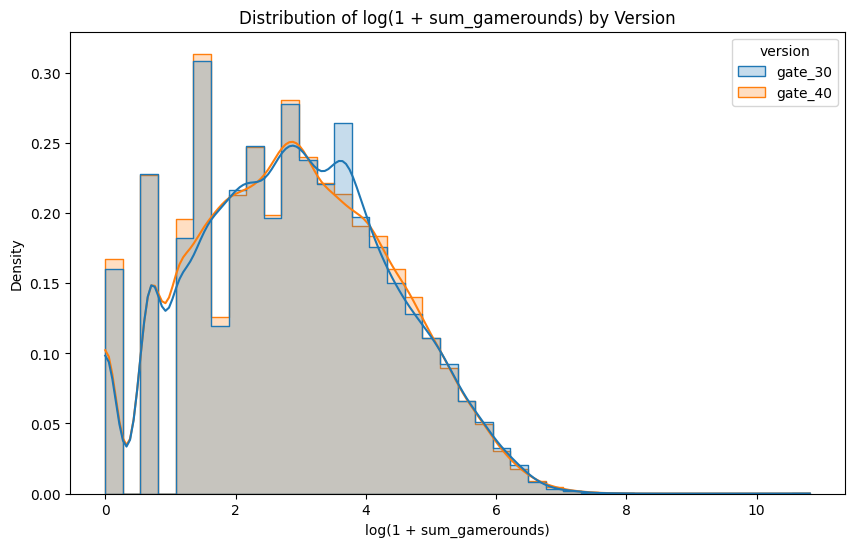

In [11]:
plt.figure(figsize=(10, 6))
sns.histplot(
    data=df,
    x=np.log1p(df["sum_gamerounds"]),
    hue="version",
    kde=True,
    element="step",
    stat="density",
    common_norm=False,
    bins=40
)
plt.title("Distribution of log(1 + sum_gamerounds) by Version")
plt.xlabel("log(1 + sum_gamerounds)")
plt.ylabel("Density")
plt.show()

### Interpretation: Player Activity

The distribution of `sum_gamerounds` is highly right-skewed in both experimental groups, indicating that most players complete relatively few rounds while a small number of players exhibit exceptionally high activity.

The control group (`gate_30`) has a slightly higher mean (52.46 vs. 51.30) and median (17 vs. 16) number of rounds than the treatment group (`gate_40`).

These descriptive results suggest a small advantage for `gate_30` in observed player activity. However, the distributions contain extreme values, particularly in the control group, which may influence the mean.

Therefore, the activity comparison should be interpreted cautiously. Additional robust statistical analysis is required to determine whether the groups differ reliably in player activity.

The statistically significant Day 7 retention difference remains the stronger evidence supporting the decision to maintain the gate at level 30.

/opt/conda/lib/python3.10/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


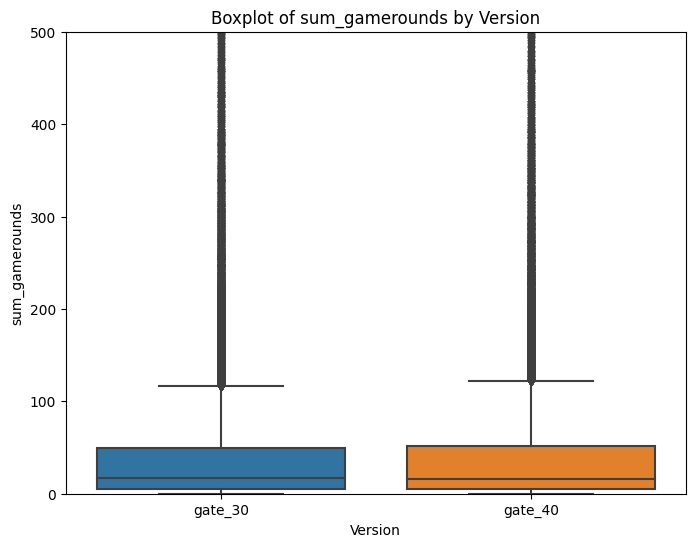

In [12]:
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x="version", y="sum_gamerounds")
plt.title("Boxplot of sum_gamerounds by Version")
plt.xlabel("Version")
plt.ylabel("sum_gamerounds")
plt.ylim(0, 500)  # extreme outlierları bastırmak için
plt.show()

## Interpretation: Bayesian Perspective

As an additional perspective, I used a Bayesian approach to compare the day-1 retention and day-7 retention rates of the two groups.



retention_1
P(gate_40 > gate_30): 3.73%
P(gate_30 > gate_40): 96.27%
95% credible interval (B - A): [-1.24%, 0.06%]


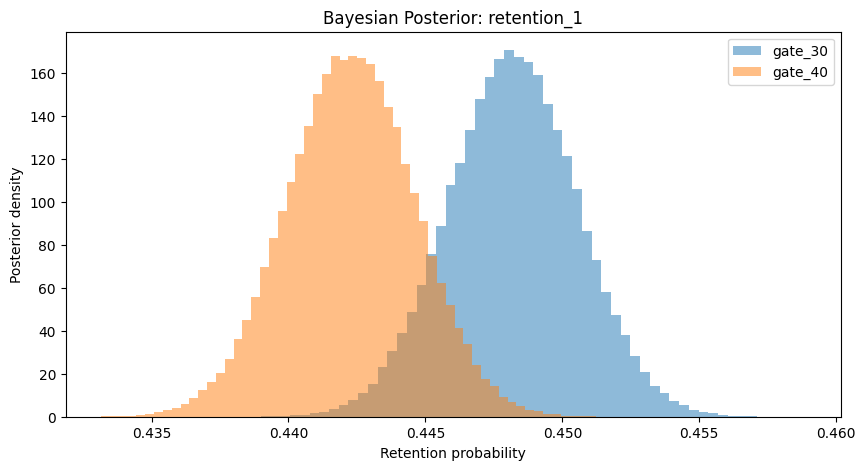


retention_7
P(gate_40 > gate_30): 0.08%
P(gate_30 > gate_40): 99.92%
95% credible interval (B - A): [-1.33%, -0.31%]


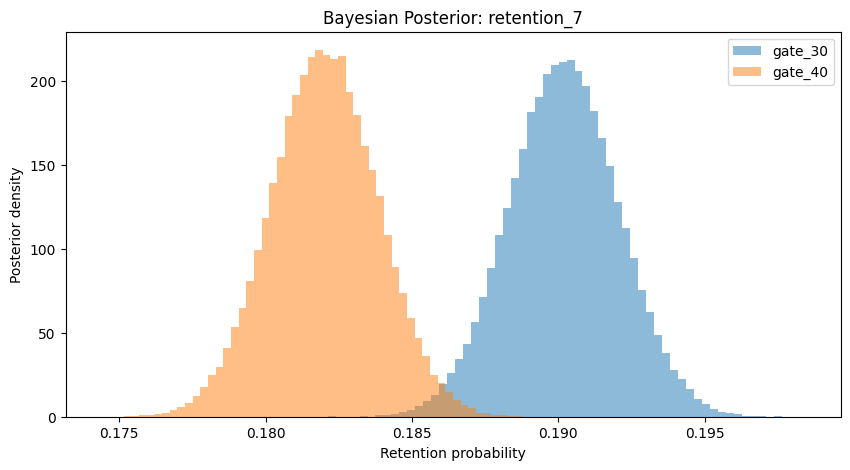

In [13]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

for metric in ['retention_1', 'retention_7']:

    data_A = df[df['version'] == 'gate_30'][metric].dropna()
    data_B = df[df['version'] == 'gate_40'][metric].dropna()

    success_A = int(data_A.sum())
    success_B = int(data_B.sum())

    trials_A = len(data_A)
    trials_B = len(data_B)

    # Beta(1,1) prior
    alpha_A = 1 + success_A
    beta_A = 1 + trials_A - success_A

    alpha_B = 1 + success_B
    beta_B = 1 + trials_B - success_B

    # Posterior samples
    samples_A = np.random.beta(alpha_A, beta_A, 100000)
    samples_B = np.random.beta(alpha_B, beta_B, 100000)

    # Posterior probability
    prob_B_superior = np.mean(samples_B > samples_A)

    # Credible interval for the difference (B - A)
    diff = samples_B - samples_A
    ci_low, ci_high = np.percentile(diff, [2.5, 97.5])

    print(f"\n{metric}")
    print(f"P(gate_40 > gate_30): {prob_B_superior:.2%}")
    print(f"P(gate_30 > gate_40): {1-prob_B_superior:.2%}")
    print(
        f"95% credible interval (B - A): "
        f"[{ci_low:.2%}, {ci_high:.2%}]"
    )

    # Plot posterior distributions
    plt.figure(figsize=(10, 5))
    plt.hist(
        samples_A, bins=60, alpha=0.5,
        density=True, label='gate_30'
    )
    plt.hist(
        samples_B, bins=60, alpha=0.5,
        density=True, label='gate_40'
    )

    plt.title(f'Bayesian Posterior: {metric}')
    plt.xlabel('Retention probability')
    plt.ylabel('Posterior density')
    plt.legend()
    plt.show()

### Interpretation: Bayesian Analysis

A Bayesian beta-binomial model was used to compare Day 1 and Day 7 retention between the control (`gate_30`) and treatment (`gate_40`) groups.

**Day 1 Retention**

The posterior probability that `gate_40` has higher retention than `gate_30` is approximately **3.73%**, while the probability favoring `gate_30` is **96.27%**.

The 95% credible interval for the retention difference (`gate_40` minus `gate_30`) ranges from −1.24 to +0.06 percentage points, indicating uncertainty about the direction of the difference.

**Day 7 Retention**

The probability that `gate_40` has higher retention is approximately **0.08%**, while the probability favoring `gate_30` is **99.92%**.

The 95% credible interval for the difference ranges from −1.33 to −0.31 percentage points, indicating that the posterior distribution strongly favors `gate_30`.

**Business Interpretation**

The Bayesian results favor retaining the gate at level 30, particularly for Day 7 retention.

However, posterior probabilities do not measure the commercial importance of the difference. The business decision should also consider effect size, player activity, and longer-term product performance.

## Final Conclusion & Business Recommendation

### Business Objective

The objective of this A/B test was to evaluate whether moving the first progression gate in Cookie Cats from level 30 (`gate_30`) to level 40 (`gate_40`) improves player retention and engagement.

### Key Findings

**1. Day 1 Retention**

- `gate_30`: 44.82%
- `gate_40`: 44.23%
- P-value: 0.0744

The difference in Day 1 retention was not statistically significant at the 5% significance level. Therefore, there is insufficient evidence to conclude that changing the gate placement affects Day 1 retention.

**2. Day 7 Retention**

- `gate_30`: 19.02%
- `gate_40`: 18.20%
- P-value: 0.00155

Day 7 retention was statistically significantly higher in the `gate_30` group.

The absolute difference was approximately **0.82 percentage points**, suggesting that retaining the gate at level 30 supports better medium-term player retention.

This result also remains statistically significant when applying a Bonferroni correction for the two retention tests.

**3. Player Activity**

The original mean number of game rounds was slightly higher in `gate_30` (52.46) than in `gate_40` (51.30).

However, after excluding the single largest observation of 49,854 rounds in a sensitivity analysis, the means became almost identical (51.34 vs. 51.30).

This indicates that the original difference in mean activity was largely influenced by one extreme observation.

**4. Bayesian Analysis**

The Bayesian analysis also favored `gate_30`, particularly for Day 7 retention.

The estimated posterior probability that `gate_30` has higher Day 7 retention was approximately 99.92% under the selected beta-binomial model.

However, this probability should not be interpreted as the magnitude or commercial importance of the difference.

### Business Recommendation

**Recommendation: Keep the first progression gate at level 30.**

The A/B test provides statistically significant evidence that `gate_30` achieves better Day 7 retention than `gate_40`.

Moving the gate to level 40 did not demonstrate an improvement in Day 1 retention and was associated with lower Day 7 retention.

Since maintaining player retention is important for long-term engagement and potential monetization, retaining the existing gate placement is the preferable decision based on the available evidence.

### Limitations

- The analysis focuses on Day 1 and Day 7 retention rather than longer-term retention.
- Monetization metrics, such as in-app purchases and revenue per player, are unavailable.
- The player activity distribution contains extreme values, making comparisons of mean game rounds sensitive to outliers.
- The analysis does not explain the underlying behavioral reasons for the observed retention difference.

### Next Steps

- Investigate level progression and potential friction around the progression gates.
- Analyze longer-term retention and monetization if additional data becomes available.
- Evaluate future gate placement changes through controlled experiments.
- Monitor retention and engagement metrics after implementing product decisions.

### Key Takeaway

**Moving a progression gate to a later level does not necessarily improve player engagement.**

This experiment demonstrates how A/B testing, statistical hypothesis testing, Bayesian analysis, and sensitivity analysis can support evidence-based game design decisions.